In [ ]:
import pandas as pd

df = pd.read_csv("pakistan_air_quality_monthly_2015_2025.csv")
df.head()


,year,month,month_name,city,province,region,latitude,longitude,population_millions,pm25_ugm3,...,who_guideline_ratio,is_smog_season,is_crop_burning_season,is_monsoon_season,season,covid_lockdown_period,data_source,data_quality,pakistan_national_avg_pm25,pakistan_global_rank
0,2015,1,January,Faisalabad,Punjab,Central Punjab,31.4187,73.0791,3.8,266.3,...,53.3,1,0,0,Winter (Smog Season),0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN
1,2015,2,February,Faisalabad,Punjab,Central Punjab,31.4187,73.0791,3.8,237.7,...,47.5,1,0,0,Winter (Smog Season),0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN
2,2015,3,March,Faisalabad,Punjab,Central Punjab,31.4187,73.0791,3.8,145.0,...,29.0,0,0,0,Spring,0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN
3,2015,4,April,Faisalabad,Punjab,Central Punjab,31.4187,73.0791,3.8,74.7,...,14.9,0,0,0,Spring,0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN
4,2015,5,May,Faisalabad,Punjab,Central Punjab,31.4187,73.0791,3.8,59.6,...,11.9,0,0,0,Summer/Monsoon,0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN


In [ ]:
lahore_df = df[df['city'] == 'Lahore']
lahore_df.head()

,year,month,month_name,city,province,region,latitude,longitude,population_millions,pm25_ugm3,...,who_guideline_ratio,is_smog_season,is_crop_burning_season,is_monsoon_season,season,covid_lockdown_period,data_source,data_quality,pakistan_national_avg_pm25,pakistan_global_rank
660,2015,1,January,Lahore,Punjab,North Punjab,31.5204,74.3587,14.0,195.1,...,39.0,1,0,0,Winter (Smog Season),0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN
661,2015,2,February,Lahore,Punjab,North Punjab,31.5204,74.3587,14.0,175.3,...,35.1,1,0,0,Winter (Smog Season),0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN
662,2015,3,March,Lahore,Punjab,North Punjab,31.5204,74.3587,14.0,104.6,...,20.9,0,0,0,Spring,0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN
663,2015,4,April,Lahore,Punjab,North Punjab,31.5204,74.3587,14.0,57.1,...,11.4,0,0,0,Spring,0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN
664,2015,5,May,Lahore,Punjab,North Punjab,31.5204,74.3587,14.0,43.1,...,8.6,0,0,0,Summer/Monsoon,0,IQAir World Air Quality Report 2018-2025 / IQA...,Estimated (pre-monitoring era),NaN,NaN


In [ ]:
print(lahore_df.shape)
print(lahore_df.isna().sum())


(132, 23)
year                           0
month                          0
month_name                     0
city                           0
province                       0
region                         0
latitude                       0
longitude                      0
population_millions            0
pm25_ugm3                      0
aqi_us                         0
aqi_category                   0
annual_pm25_avg_ugm3           0
who_guideline_ratio            0
is_smog_season                 0
is_crop_burning_season         0
is_monsoon_season              0
season                         0
covid_lockdown_period          0
data_source                    0
data_quality                   0
pakistan_national_avg_pm25    36
pakistan_global_rank          36
dtype: int64


In [ ]:
lahore_df = lahore_df.sort_values(['year', 'month']).reset_index(drop=True)
lahore_df['aqi_last_month'] = lahore_df['aqi_us'].shift(1)
lahore_df[['year', 'month', 'aqi_us', 'aqi_last_month']].head(10)

,year,month,aqi_us,aqi_last_month
0,2015,1,245,NaN
1,2015,2,226,245.0
2,2015,3,176,226.0
3,2015,4,152,176.0
4,2015,5,120,152.0
5,2015,6,113,120.0
6,2015,7,132,113.0
7,2015,8,153,132.0
8,2015,9,160,153.0
9,2015,10,186,160.0


In [ ]:
lahore_df = lahore_df.dropna(subset=['aqi_last_month'])

features = ['aqi_last_month', 'month', 'is_smog_season', 'is_crop_burning_season', 'is_monsoon_season']
target = 'aqi_us'

X = lahore_df[features]
y = lahore_df[target]

X.head()

,aqi_last_month,month,is_smog_season,is_crop_burning_season,is_monsoon_season
1,245.0,2,1,0,0
2,226.0,3,0,0,0
3,176.0,4,0,0,0
4,152.0,5,0,0,0
5,120.0,6,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 7.423991569920419


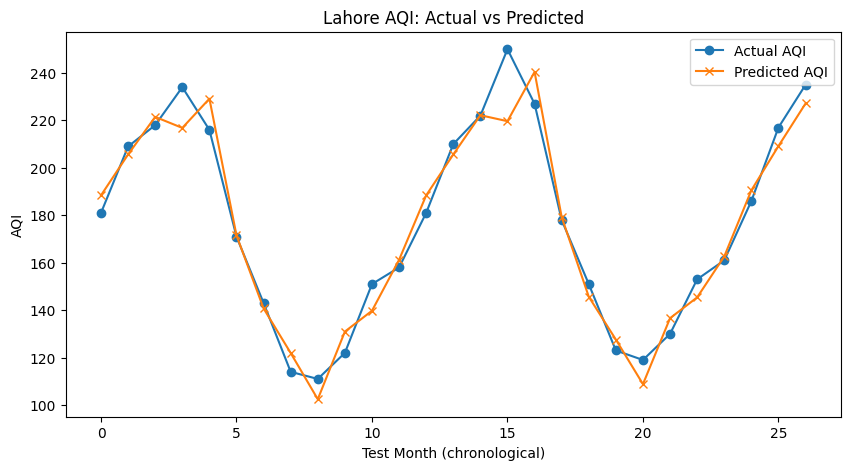

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(y_test.values, label="Actual AQI", marker='o')
plt.plot(predictions, label="Predicted AQI", marker='x')
plt.title("Lahore AQI: Actual vs Predicted")
plt.xlabel("Test Month (chronological)")
plt.ylabel("AQI")
plt.legend()
plt.show()

In [ ]:
import pandas as pd
coef_df = pd.DataFrame({'feature': features, 'importance': model.coef_})
print(coef_df)

                  feature  importance
0          aqi_last_month    0.706412
1                   month    0.999557
2          is_smog_season   45.910066
3  is_crop_burning_season    4.953089
4       is_monsoon_season   29.635846
